<a href="https://colab.research.google.com/github/reitezuz/18NES2-2026/blob/main/week07/pets_denoise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image denoising — removing noise from Oxford-IIIT Pet images

Adapted from François Chollet’s image segmentation example:
https://github.com/fchollet/deep-learning-with-python-notebooks/blob/master/chapter11_image-segmentation.ipynb

The Oxford-IIIT Pet Dataset (https://www.robots.ox.ac.uk/~vgg/data/pets/) contains color images of 37 cat and dog breeds, with roughly 200 images per breed. The images vary in lighting, scale, and pose.

In this notebook, we use these images for **image denoising**. We add Gaussian noise to the original images and train an encoder–decoder network to reconstruct the clean images from their noisy versions. The original images serve as targets; segmentation masks are not needed.

Download the images:
https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz

## Download and preprocess the data
1. Download the zip file with the data
2. Extract the zip file

In [1]:
!wget https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz
!tar -xf images.tar.gz

import os
# Clean up by removing the downloaded archive.
os.remove("images.tar.gz")


--2026-11-10 13:06:21--  https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz
Resolving thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)... 129.67.95.98
Connecting to thor.robots.ox.ac.uk (thor.robots.ox.ac.uk)|129.67.95.98|:443... connected.
HTTP request sent, awaiting response... 308 Permanent Redirect
Location: https://thor.robots.ox.ac.uk/pets/images.tar.gz [following]
--2026-11-10 13:06:21--  https://thor.robots.ox.ac.uk/pets/images.tar.gz
Reusing existing connection to thor.robots.ox.ac.uk:443.
HTTP request sent, awaiting response... 200 OK
Length: 791918971 (755M) [application/octet-stream]
Saving to: ‘images.tar.gz’

images.tar.gz       100%[===================>] 755.23M  26.5MB/s    in 13s     

2026-11-10 13:06:34 (56.4 MB/s) - ‘images.tar.gz’ saved [791918971/791918971]



### The format (structure) of the folders with data:
The root folder contains two main subdirectories:
- **`images/`**: Contains all the pet images for all classes in a single directory. Each image file is named according to the pet's breed (e.g., `Abyssinian_1.jpg`).
- **`annotations/`**: Contains metadata such as class labels, train-test splits, and segmentation masks.
  - **`trainval.txt`**: Contains a list of images designated for training and validation, along with their class labels and species (dog or cat).
  - **`test.txt`**: Contains a list of images reserved for testing.
  - **`trimaps/`**: Stores pixel-level segmentation masks for each image, representing:
    - Foreground (1)
    - Background (2)
    - Object boundaries (3).


### Observe the data

In [2]:
# Create lists of paths to files:
# input_img_paths ... image paths
import os

input_dir = "images/"

input_img_paths = sorted([os.path.join(input_dir, fname)  for fname in os.listdir(input_dir)  if fname.endswith(".jpg")])
print(input_img_paths[:3])


['images/Abyssinian_1.jpg', 'images/Abyssinian_10.jpg', 'images/Abyssinian_100.jpg']


Image path: images/Abyssinian_124.jpg


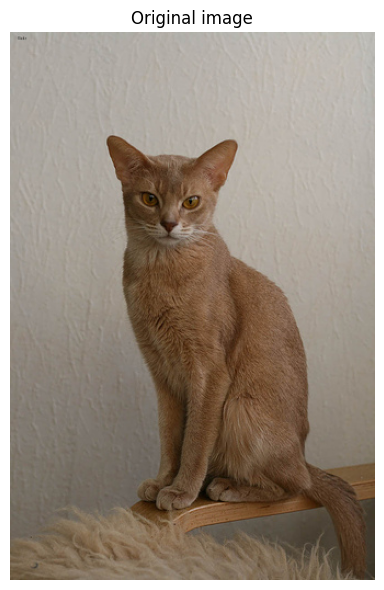

In [3]:
# View an original image
image_index = 28  # Change the index as needed

import matplotlib.pyplot as plt
from keras.utils import load_img, img_to_array

print(f"Image path: {input_img_paths[image_index]}")

image = load_img(input_img_paths[image_index])

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Original image")
plt.axis("off")
plt.tight_layout()
plt.show()

### Create training, validation and test sets as numpy arrays


In [5]:
# Load, resize, and split images into training, validation, and test sets.
import numpy as np
import random
from keras.utils import load_img, img_to_array

img_size = (200, 200)  # Resize images to the same size.
num_imgs = len(input_img_paths)

random.Random(1337).shuffle(input_img_paths)

def path_to_input_image(path):
    return img_to_array(load_img(path, target_size=img_size))

input_imgs = np.zeros((num_imgs,) + img_size + (3,), dtype="float32")
for i in range(num_imgs):
    input_imgs[i] = path_to_input_image(input_img_paths[i])

# Normalize the original array in place.
input_imgs /= 255.0

num_val_samples = 1000  # Number of samples in each validation/test set.
train_input_imgs = input_imgs[:-2 * num_val_samples]
val_input_imgs = input_imgs[-2 * num_val_samples:-num_val_samples]
test_input_imgs = input_imgs[-num_val_samples:]

print(f"Number of training samples: {train_input_imgs.shape[0]}")
print(f"Number of validation samples: {val_input_imgs.shape[0]}")
print(f"Number of test samples: {test_input_imgs.shape[0]}")

Number of training samples: 5390
Number of validation samples: 1000
Number of test samples: 1000


In [6]:
# Prepare noisy inputs and clean targets

train_targets = train_input_imgs
val_targets = val_input_imgs
test_targets = test_input_imgs

noise_std = 0.15
rng = np.random.default_rng(1337)

def add_noise(images, noise_std):
    noisy_images = np.empty_like(images)

    for i in range(len(images)):
        # Generate float32 noise for one image at a time.
        noise = rng.standard_normal(
            size=images[i].shape, dtype=np.float32
        )
        noise *= noise_std
        np.add(images[i], noise, out=noisy_images[i])
        np.clip(noisy_images[i], 0.0, 1.0, out=noisy_images[i])

    return noisy_images

train_noisy_imgs = add_noise(train_targets, noise_std)
val_noisy_imgs = add_noise(val_targets, noise_std)
test_noisy_imgs = add_noise(test_targets, noise_std)

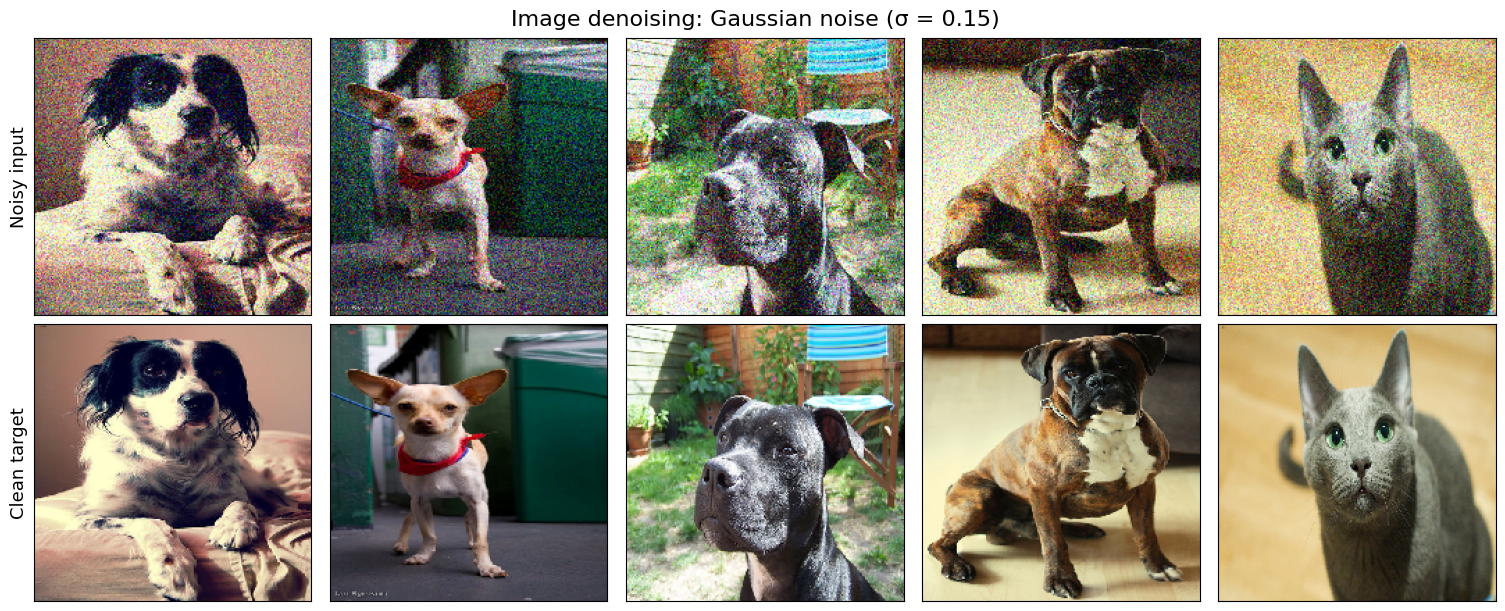

In [7]:
import numpy as np
import matplotlib.pyplot as plt

num_examples = 5
indices = np.random.default_rng(42).choice(
    len(train_targets), size=num_examples, replace=False
)

fig, axes = plt.subplots(
    2, num_examples, figsize=(15, 6), constrained_layout=True
)

for col, idx in enumerate(indices):
    axes[0, col].imshow(train_noisy_imgs[idx])
    axes[1, col].imshow(train_targets[idx])

    for row in range(2):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

axes[0, 0].set_ylabel("Noisy input", fontsize=13)
axes[1, 0].set_ylabel("Clean target", fontsize=13)

fig.suptitle(
    f"Image denoising: Gaussian noise (σ = {noise_std})",
    fontsize=16
)
plt.show()

## Define and train the model

### Simple CNN autoencoder model to denoise the image:


Model: "pool_unpool_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 50, 50, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 100, 100, 256)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 100, 100, 128)  │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 200, 200, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 200, 200, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 200, 200, 3)    │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,331,459 (5.08 MB)

 Trainable params: 1,331,459 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

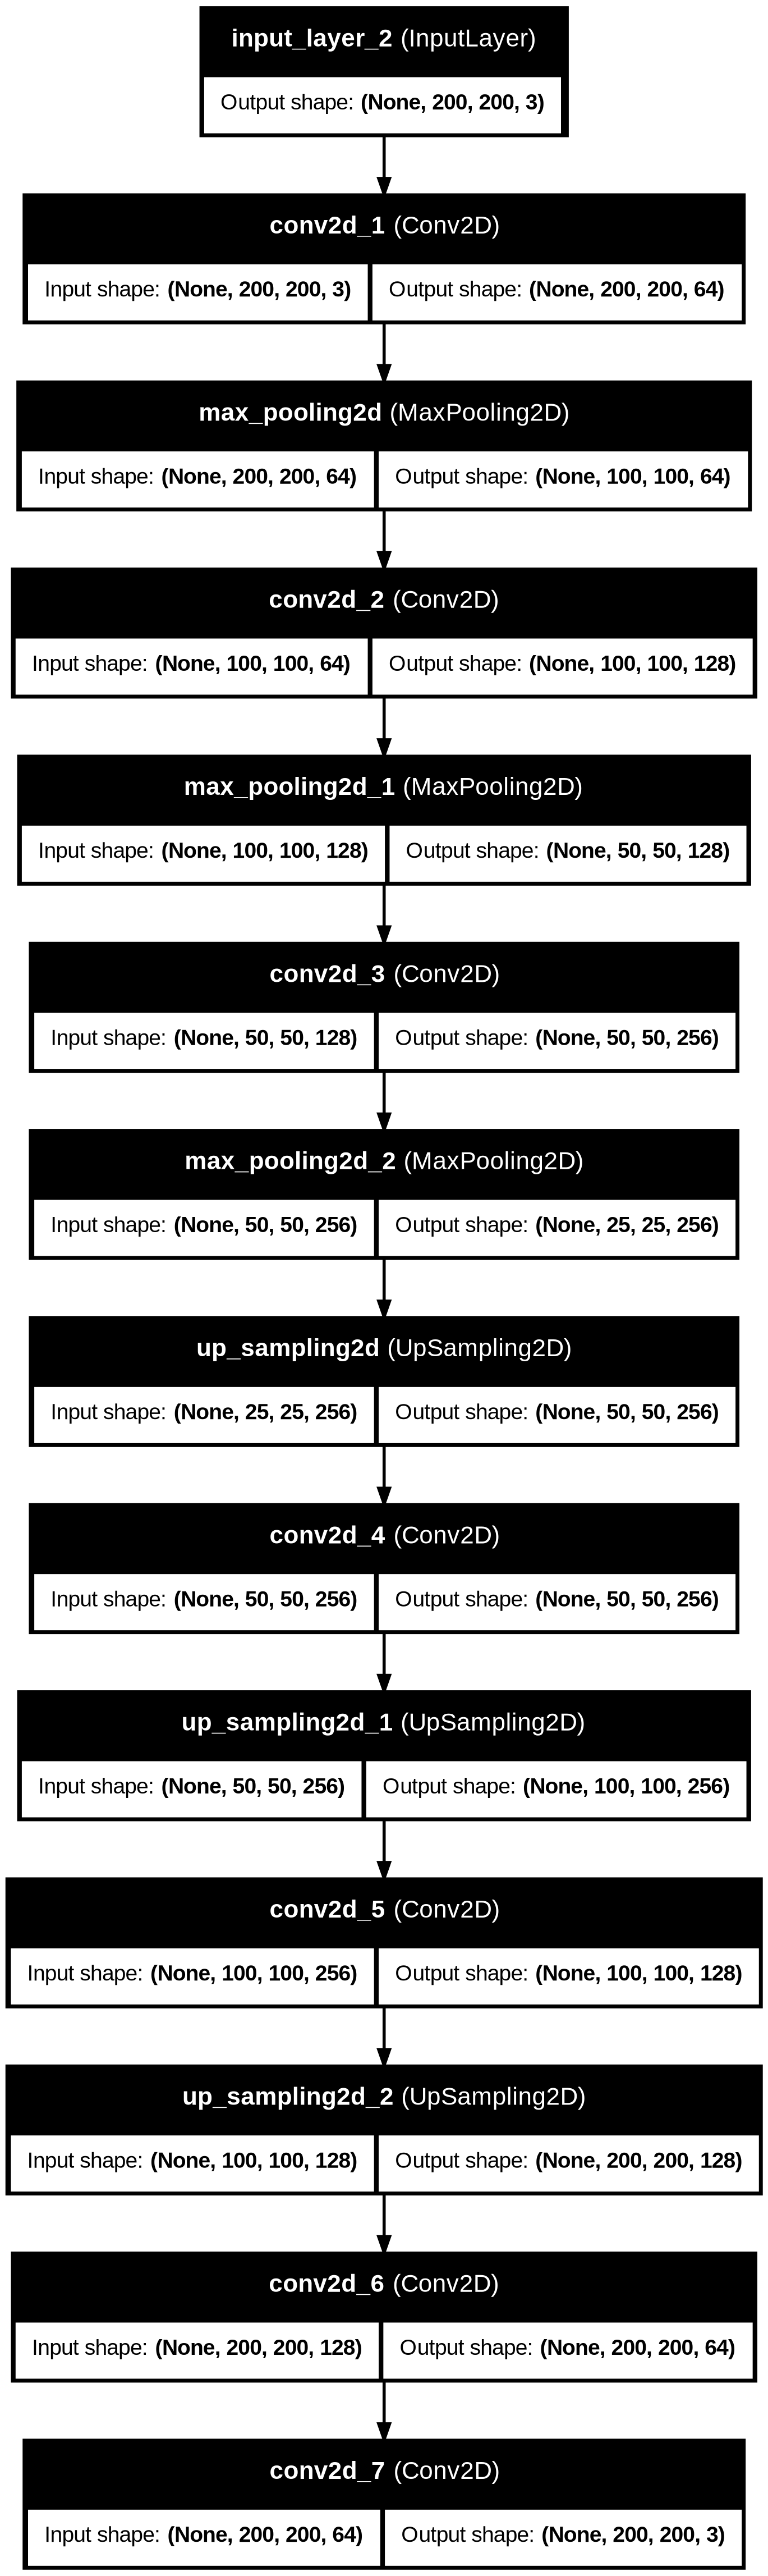

In [11]:
# Define the model architecture
import keras, keras.layers as layers
def get_autoencoder_pool_unpool(img_size):
    inputs = keras.Input(shape=img_size + (3,))
    #x = layers.Rescaling(1./255)(inputs)

    # Encoder: Conv + MaxPooling -----
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D(pool_size=2, padding="same")(x)   # 1/2 resolution

    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(pool_size=2, padding="same")(x)   # 1/4 resolution

    x = layers.Conv2D(256, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D(pool_size=2, padding="same")(x)   # 1/8 resolution

    # Latent space
    latent = x

    # Decoder: nearest-neighbor upsampling + convolution
    x = layers.UpSampling2D(size=2)(latent)                   # 1/4 resolution
    x = layers.Conv2D(256, 3, activation="relu", padding="same")(x)

    x = layers.UpSampling2D(size=2)(x)                        # 1/2 resolution
    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)

    x = layers.UpSampling2D(size=2)(x)                        # original resolution
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)

    # Reconstruct RGB image - difference:
    outputs = layers.Conv2D(3, 3, activation="sigmoid", padding="same")(x)

    model = keras.Model(inputs, outputs, name="pool_unpool_autoencoder")
    return model

model = get_autoencoder_pool_unpool(img_size=(200, 200))
model.summary()

keras.utils.plot_model(model, to_file="autoencoder_model.png", show_shapes=True, show_layer_names=True)
from IPython.display import Image, display
display(Image(filename="autoencoder_model.png", width=300))



In [12]:
# Data frame for denoising results
import pandas as pd

columns = [
    "Model Name", "Test MAE", "Test Loss", "Train MAE", "Train Loss", "Time (s)", "Epochs", "Details"
]
denoising_results_df = pd.DataFrame(columns=columns)

In [13]:
# Plot the training progress:
def plot_history(history):
    history_dict = history.history
    print(history_dict.keys())

    from matplotlib import pyplot as plt

    plt.plot(history_dict['mae'])
    plt.plot(history_dict['val_mae'])
    plt.title('Model MAE')
    plt.ylabel('Mean absolute error')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper right')
    plt.show()

    # Plot training & validation loss values
    plt.plot(history_dict['loss'])
    plt.plot(history_dict['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Mean squared error')  # CHANGED
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper right')
    plt.show()

### Train the model

In [ ]:
# Set some of the hyperparameters:
do_early_stopping = False
do_tensorboard = True
do_checkpoint = True
max_epochs = 30
batch_size = 16
model_name = 'pets_denoising_from_scratch.keras'  # CHANGED

details = ""  # your comment

import keras
from keras import layers
import datetime
import os
import pandas as pd

# ADDED: Create the directory before checkpointing.
model_dir = "./models/"
os.makedirs(model_dir, exist_ok=True)

###############################################
# Define the model architecture:
# CHANGED: Adapt this function to return an RGB image in [0, 1].
model = get_autoencoder_pool_unpool(img_size=img_size)
model.summary()

# Configure the model:
model.compile(
    optimizer=keras.optimizers.Adam(),
    loss=keras.losses.MeanSquaredError(),                  # CHANGED
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")]  # CHANGED
)

###############################################
# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )
    callbacks.append(early_stopping)

if do_checkpoint:
    from keras.callbacks import ModelCheckpoint
    checkpoint = keras.callbacks.ModelCheckpoint(
        filepath=model_dir + model_name,
        save_best_only=True,
        monitor="val_loss"
    )
    callbacks.append(checkpoint)

if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(
        log_dir="./logs_pets/" + model_name,
        histogram_freq=1,
        write_steps_per_second=True
    )
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()

history = model.fit(
    train_noisy_imgs, train_targets,                  # CHANGED
    epochs=max_epochs,
    validation_data=(val_noisy_imgs, val_targets),    # CHANGED
    batch_size=batch_size,
    callbacks=callbacks
)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
epochs = range(1, len(history.epoch) + 1)

for ax, metric, title in zip(
    axes, ["loss", "mae"], ["Mean squared error (loss)", "Mean absolute error"]
):
    ax.plot(epochs, history.history[metric], label="Training")
    ax.plot(epochs, history.history["val_" + metric], label="Validation")
    ax.set_xlabel("Epoch")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.show()

if do_checkpoint:
    # Load the best model
    model = keras.models.load_model(model_dir + model_name)

train_loss, train_mae = model.evaluate(train_noisy_imgs, train_targets, batch_size=batch_size)
val_loss, val_mae = model.evaluate(val_noisy_imgs, val_targets, batch_size=batch_size)
test_loss, test_mae = model.evaluate(test_noisy_imgs, test_targets, batch_size=batch_size)


print(f"Training MSE: {train_loss:.6f}, MAE: {train_mae:.6f}")
print(f"Validation MSE: {val_loss:.6f}, MAE: {val_mae:.6f}")
print(f"Test MSE: {test_loss:.6f}, MAE: {test_mae:.6f}")

###############################
# Save the model:
model.save(model_dir + model_name)

#################################
# Add results to the dataframe:
model_details = f"{do_early_stopping}-ep.:{max_epochs}-bs:{batch_size} {details}"
new_entry = {
    "Model Name": model_name,
    "Details": model_details,
    "Test MAE": test_mae,
    "Test Loss": test_loss,
    "Train MAE": train_mae,
    "Train Loss": train_loss,
    "Time (s)": time_fit,
    "Epochs": len(history.epoch),
}

if (
    'denoising_results_df' not in locals()
    or denoising_results_df is None
    or denoising_results_df.empty
):
    denoising_results_df = pd.DataFrame([new_entry])
else:
    denoising_results_df = pd.concat(
        [denoising_results_df, pd.DataFrame([new_entry])],
        ignore_index=True
    )

# View and save the dataframe:
denoising_results_df.to_csv(
    model_dir + "pets_denoising_results.csv", index=False
)
print("Results:")
display(denoising_results_df)

Model: "pool_unpool_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 200, 200, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 25, 25, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 50, 50, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_4 (UpSampling2D)  │ (None, 100, 100, 256)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 100, 100, 128)  │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_5 (UpSampling2D)  │ (None, 200, 200, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 200, 200, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 200, 200, 3)    │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,331,459 (5.08 MB)

 Trainable params: 1,331,459 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

### Observations
- The model starts overfitting around epoch 10-25

## View some denoised images from the test set

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

num_examples = 5
indices = np.random.default_rng(42).choice(
    len(test_noisy_imgs), size=num_examples, replace=False
)

# Predict clean images from noisy test images.
noisy_images = test_noisy_imgs[indices]
clean_images = test_targets[indices]
denoised_images = model.predict(noisy_images, verbose=0)

fig, axes = plt.subplots(
    num_examples, 3,
    figsize=(10, 3 * num_examples),
    squeeze=False,
    constrained_layout=True
)

titles = ["Noisy input", "Denoised image", "Clean target"]

for row in range(num_examples):
    images = [
        noisy_images[row],
        denoised_images[row],
        clean_images[row]
    ]

    for col, image in enumerate(images):
        axes[row, col].imshow(np.clip(image, 0, 1))
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(titles[col], fontsize=14)

fig.suptitle("Image denoising — test examples", fontsize=16)
plt.show()

In [ ]:
###############################################
# Load TensorBoard notebook extension
%load_ext tensorboard

# Start TensorBoard before training begins
%tensorboard --logdir ./logs_pets/ --reload_interval=1